# Deploy a modern pretrained colorization reference
        Separate local training from externally trained models and compare the same test
        population. [DDColor protocol](../docs/11_image_restoration.md#frozen-ddcolor-reference)
        and [photo attribution](../docs/photo_attributions.md).

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
root = Path.cwd()
while not (root / 'pyproject.toml').exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root / 'src'))
def evidence(study):
    return json.loads((root / 'results' / 'reference' / study / 'metrics.json').read_text())
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False, 'axes.spines.right': False})

In [2]:
external = evidence('ddcolor')
record = json.loads((root/'results/reference/ddcolor/run.json').read_text())
pd.Series({'source_revision':record['config']['source_revision'],
           'model_revision':record['config']['model_revision'],
           'weight_sha256':external['weight_sha256'],
           'parameters':external['parameters'],
           'images_per_second':external['images_per_second']})

source_revision               2adb63f2656ac41cbdf7b894cddd94121a3faf13
model_revision                060f67494e31883a4b13cb27f889f3154847ada4
weight_sha256        d81711971ec59200da26d5e8a1afae8dd3778d495ea8ad...
parameters                                                   227869328
images_per_second                                            33.944679
dtype: object

In [3]:
local = evidence('colorization')
pd.DataFrame([{'model':r['model'],'seed':r.get('seed'),'psnr':r['psnr']['mean'],
              'delta_e76':r['delta_e76']['mean'],'chroma':r['mean_chroma']['mean']}
             for r in local['rows']+external['rows']])

,model,seed,psnr,delta_e76,chroma
0,neutral_gray,NaN,25.311615,15.964154,0.000000
1,autoencoder_l2,0.0,23.387108,14.378936,9.291015
2,transfer_l2,0.0,23.777885,13.776851,10.681240
3,transfer_balanced_bins,0.0,22.950842,15.551892,14.372451
4,autoencoder_l2,1.0,23.379766,14.423375,8.899590
5,transfer_l2,1.0,23.564901,14.223806,10.832904
6,transfer_balanced_bins,1.0,22.885869,15.443452,14.152438
7,ddcolor_modelscope_frozen,NaN,22.973745,14.984932,16.081902


## Compare paired errors without conflating exposure
        The same photographs enter both tests. ImageNet exposure and the released model's
        task-specific training are additional resources; it is not an equal-data comparison.
        Possible overlap with external training was not audited.

In [4]:
own_scores = np.load(root/'assets/source_data/colorization_per_image_scores.npz')
external_scores = np.load(root/'assets/source_data/ddcolor_per_image_scores.npz')
own = [r for r in local['rows'] if r['model']=='transfer_l2']
delta = external_scores[external['rows'][0]['per_image_psnr_key']] - np.mean([own_scores[r['per_image_psnr_key']] for r in own],axis=0)
print('Paired external-minus-local PSNR (dB):',delta.mean())
print('Fraction of images with higher external-model PSNR:',np.mean(delta>0))

Paired external-minus-local PSNR (dB): -0.6976483380794525
Fraction of images with higher external-model PSNR: 0.4075


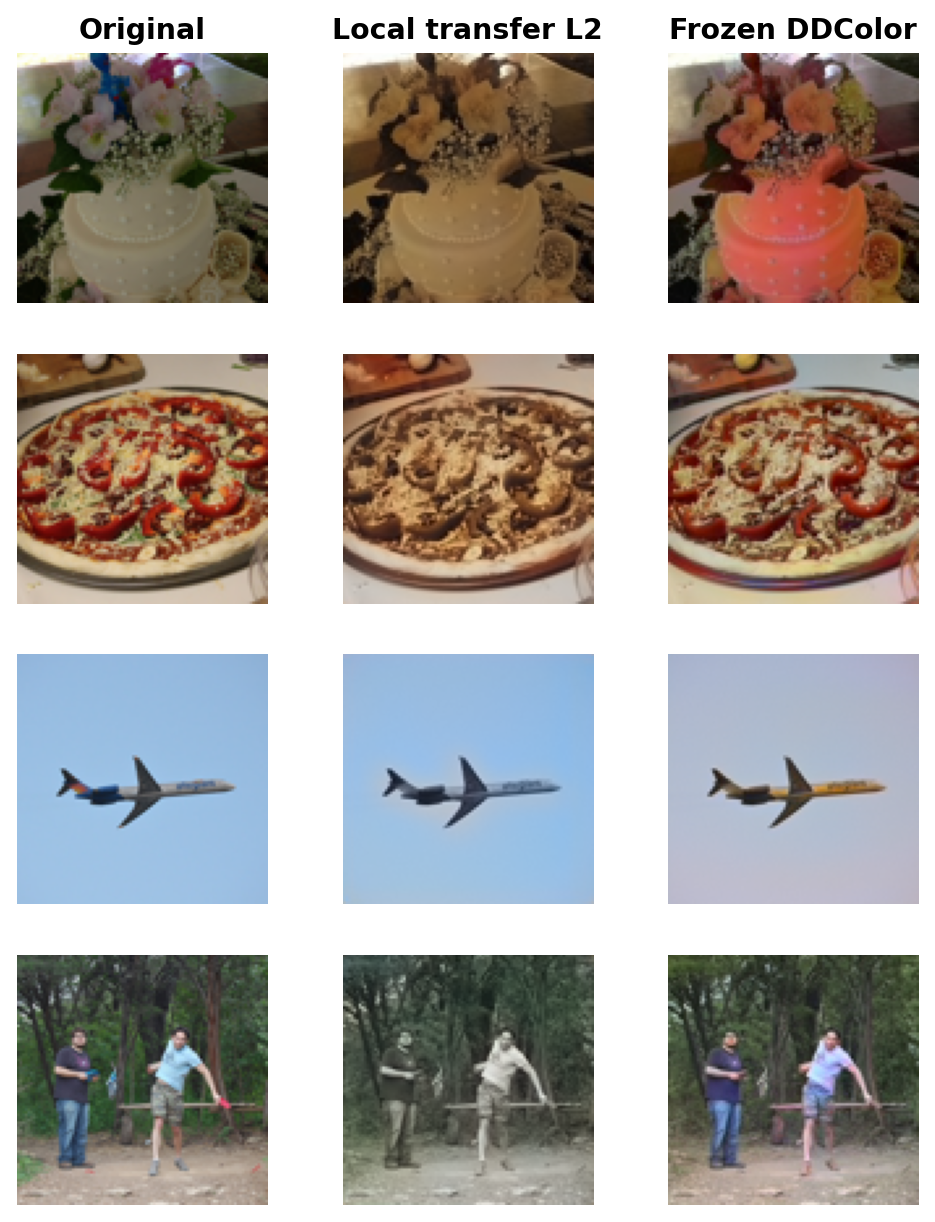

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root/'assets/ddcolor_gallery.png')))

## Worked answer
        Why upsample only lightness-derived gray for DDColor? Resizing RGB and then taking
        Lab lightness can let source chroma influence the input through a nonlinear color
        conversion. The adapter takes native-resolution L, reconstructs neutral gray and
        only then resizes. A 512px internal tensor does not supply additional observed detail.